# 06 · Ciblage des appels par boutique (question 6)

Atelier Saint-Honoré · Lot 3 · branche `lot3-churn-appels`

## La question posée par la direction

> Chaque boutique peut passer 40 appels par mois. À qui ? On préfère rater quelques clients que de faire appeler des gens qui seraient revenus de toute façon.

## Comment nous la comprenons

Nous réutilisons le modèle de départ du notebook 05 : chaque client a une probabilité de départ. Il faut maintenant transformer ces probabilités en une liste d'appels, boutique par boutique, avec 40 appels maximum.

La phrase importante est la deuxième : appeler un client qui serait revenu seul, c'est du temps perdu pour le vendeur. Nous préférons donc la **précision** (parmi les clients appelés, un maximum sont vraiment à risque) au **rappel** (attraper tous les partants). Cela se traduit par un seuil de probabilité exigeant : on n'appelle un client que si le modèle est assez sûr de lui.

## Méthode choisie, et pourquoi

1. On part des probabilités du notebook 05, calculées hors échantillon (chaque client est prédit par un modèle qui ne l'a pas vu).
2. On choisit un seuil de probabilité d'après la précision visée, pas d'après l'exactitude globale.
3. Dans chaque boutique, on classe les clients au-dessus du seuil du plus risqué au moins risqué et on garde les 40 premiers au maximum.

Pourquoi pas un autre modèle : la répartition du travail prévoit que Q6 réutilise le modèle de Q5. De plus, ré-entraîner un modèle ici ne changerait pas la question posée, qui est un choix de seuil et de priorité, pas un choix de modèle.

Pourquoi pas le seuil par défaut de 0,5 : il traite de la même façon un client qui part et un client qui reste à tort appelé. Or la direction dit explicitement que le deuxième cas est pire.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

def trouver_racine():
    p = Path.cwd().resolve()
    for d in [p, *p.parents]:
        if (d / ".git").exists() or (d / "SaintHonore_clients.csv").exists() or (d / "data").exists():
            return d
    return p

RACINE = trouver_racine()
DOSSIER_FIG = RACINE / "reports" / "figures"
DOSSIER_FIG.mkdir(parents=True, exist_ok=True)

NB_APPELS_MAX = 40          # capacité d'une boutique par mois
PRECISION_CIBLE = 0.80      # part minimale de vrais partants parmi les appelés
SEED = 42

## 1. Chargement des fichiers

- les probabilités de départ produites par le notebook 05 ;
- la liste des 24 boutiques (ville, surface, nombre de vendeurs, ancienneté).

In [2]:
chemin_clients = RACINE / "data" / "processed" / "clients_churn_proba.csv"
if not chemin_clients.exists():
    raise FileNotFoundError(f"{chemin_clients} introuvable : lance d'abord le notebook 05.")

clients = pd.read_csv(chemin_clients)

candidats = [RACINE / "data" / "raw" / "SaintHonore_boutiques.csv",
             RACINE / "data" / "processed" / "SaintHonore_boutiques.csv",
             RACINE / "SaintHonore_boutiques.csv"]
chemin_boutiques = next((p for p in candidats if p.exists()), None)
if chemin_boutiques is None:
    raise FileNotFoundError("SaintHonore_boutiques.csv introuvable dans data/raw/.")

boutiques = pd.read_csv(chemin_boutiques, sep=None, engine="python")

print(clients.shape, boutiques.shape)
clients.head()

(700, 4) (24, 5)


,client_id,boutique,depart,proba_depart
0,CT80059,BT15,0,0.6677
1,CT80578,BT28,0,0.5185
2,CT80256,BT27,0,0.6897
3,CT80098,BT16,1,0.7268
4,CT80362,BT31,0,0.5157


In [3]:
boutiques

,boutique_id,ville,surface_m2,vendeurs,ouverte_depuis_mois
0,BT10,Dubaï,519,22,128
1,BT11,Shanghai,186,4,254
2,BT12,Cannes,288,9,167
3,BT13,Shanghai,373,25,122
4,BT14,Genève,511,20,126
5,BT15,Séoul,483,8,236
6,BT16,Paris,139,21,266
7,BT17,Paris,251,25,177
8,BT18,Cannes,259,8,141
9,BT19,Dubaï,458,7,90


## 2. Vérifier que les deux fichiers se rejoignent

Avant de croiser, on vérifie que les identifiants de boutique sont écrits pareil dans les deux fichiers.

In [4]:
def propre(s):
    return s.astype(str).str.strip().str.upper()

clients["boutique"] = propre(clients["boutique"])
boutiques["boutique_id"] = propre(boutiques["boutique_id"])

ids_clients = set(clients["boutique"])
ids_boutiques = set(boutiques["boutique_id"])

print("Boutiques des clients absentes du fichier boutiques :", sorted(ids_clients - ids_boutiques) or "aucune")
print("Boutiques sans aucun client                          :", sorted(ids_boutiques - ids_clients) or "aucune")

Boutiques des clients absentes du fichier boutiques : aucune
Boutiques sans aucun client                          : aucune


## 3. Un point à regarder : combien de clients par boutique ?

La limite est de 40 appels par boutique. Mais si une boutique n'a que 25 clients dans le fichier, la limite ne sert à rien pour elle. Regardons où elle compte vraiment.

In [5]:
nb_clients = clients.groupby("boutique").size().rename("nb_clients")
print(nb_clients.describe().round(1).to_string())
print()
print(f"Boutiques avec plus de {NB_APPELS_MAX} clients dans le fichier :", int((nb_clients > NB_APPELS_MAX).sum()), "sur", len(nb_clients))

count    24.0
mean     29.2
std       4.5
min      22.0
25%      25.8
50%      29.5
75%      33.0
max      37.0

Boutiques avec plus de 40 clients dans le fichier : 0 sur 24


## 4. Choix du seuil de probabilité

Pour chaque seuil possible, on regarde :

- combien de clients seraient appelés ;
- la **précision** : parmi eux, quelle part est vraiment partie ;
- le **rappel** : quelle part de tous les partants on attrape.

La direction préfère la précision : on cherche le plus petit seuil qui atteint la précision visée, pour rater le moins de clients possible tout en restant exigeants.

In [6]:
total_partants = clients["depart"].sum()
taux_base = clients["depart"].mean()

lignes = []
for seuil in np.round(np.arange(0.30, 0.96, 0.05), 2):
    appeles = clients[clients["proba_depart"] >= seuil]
    n = len(appeles)
    lignes.append({
        "seuil": seuil,
        "clients_appelés": n,
        "précision": appeles["depart"].mean() if n else np.nan,
        "rappel": appeles["depart"].sum() / total_partants,
        "appels_par_boutique_(moyenne)": n / clients["boutique"].nunique(),
    })

table_seuils = pd.DataFrame(lignes).round(3)
table_seuils

,seuil,clients_appelés,précision,rappel,appels_par_boutique_(moyenne)
0,0.30,687,0.590,0.983,28.625
1,0.35,669,0.590,0.959,27.875
2,0.40,636,0.596,0.920,26.500
3,0.45,585,0.617,0.876,24.375
4,0.50,519,0.634,0.799,21.625
5,0.55,445,0.640,0.692,18.542
6,0.60,348,0.647,0.546,14.500
7,0.65,245,0.661,0.393,10.208
8,0.70,143,0.699,0.243,5.958
9,0.75,76,0.763,0.141,3.167


**Lecture du tableau.** Plus le seuil monte, plus la précision monte, mais moins on appelle de monde et moins on attrape de partants. Comme les boutiques ont en moyenne une trentaine de clients dans le fichier, la limite de 40 appels n'est pas ce qui nous freine : c'est le seuil qui décide du nombre d'appels.

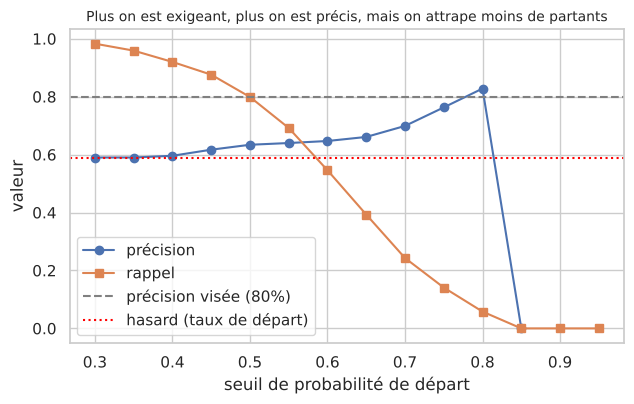

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(table_seuils["seuil"], table_seuils["précision"], marker="o", label="précision")
ax.plot(table_seuils["seuil"], table_seuils["rappel"], marker="s", label="rappel")
ax.axhline(PRECISION_CIBLE, color="gray", linestyle="--", label=f"précision visée ({PRECISION_CIBLE:.0%})")
ax.axhline(taux_base, color="red", linestyle=":", label="hasard (taux de départ)")
ax.set_xlabel("seuil de probabilité de départ")
ax.set_ylabel("valeur")
ax.set_title("Plus on est exigeant, plus on est précis, mais on attrape moins de partants")
ax.title.set_fontsize(10)
ax.legend()
plt.tight_layout()
plt.savefig(DOSSIER_FIG / "lot3_choix_du_seuil.png", dpi=150)
plt.show()

In [8]:
valides = table_seuils[(table_seuils["précision"] >= PRECISION_CIBLE) & (table_seuils["clients_appelés"] >= 20)]

if len(valides):
    SEUIL = float(valides["seuil"].min())
    print(f"Seuil retenu : {SEUIL} (plus petit seuil atteignant {PRECISION_CIBLE:.0%} de précision)")
else:
    candidats_seuil = table_seuils[table_seuils["clients_appelés"] >= 20]
    SEUIL = float(candidats_seuil.loc[candidats_seuil["précision"].idxmax(), "seuil"])
    print(f"Aucun seuil n'atteint {PRECISION_CIBLE:.0%} : on prend le seuil le plus précis avec au moins 20 clients : {SEUIL}")
    print("À expliquer dans la synthèse : le modèle ne permet pas de viser plus haut avec ces données.")

Seuil retenu : 0.8 (plus petit seuil atteignant 80% de précision)


### Fiabilité de la précision

Si peu de clients sont appelés, la précision mesurée peut être due au hasard. Pour mesurer cette incertitude, on tire 1 000 fois au hasard (avec remise) parmi les clients appelés et on regarde l'intervalle dans lequel tombe la précision (méthode du bootstrap).

In [9]:
appeles_seuil = clients[clients["proba_depart"] >= SEUIL]
rng = np.random.default_rng(SEED)
valeurs = appeles_seuil["depart"].to_numpy()

if len(valeurs) > 0:
    precisions = [rng.choice(valeurs, size=len(valeurs), replace=True).mean() for _ in range(1000)]
    bas, haut = np.percentile(precisions, [2.5, 97.5])
    print(f"Au seuil {SEUIL} : {len(valeurs)} clients, précision = {valeurs.mean():.1%}")
    print(f"Intervalle de confiance à 95 % : de {bas:.1%} à {haut:.1%}")
else:
    print("Aucun client au-dessus du seuil.")

Au seuil 0.8 : 29 clients, précision = 82.8%
Intervalle de confiance à 95 % : de 69.0% à 93.1%


## 5. Liste d'appels : les 40 premiers de chaque boutique

Dans chaque boutique, on prend les clients au-dessus du seuil, triés du plus risqué au moins risqué, et on s'arrête à 40.

In [10]:
a_risque = clients[clients["proba_depart"] >= SEUIL]

liste_appels = (a_risque
                .sort_values(["boutique", "proba_depart"], ascending=[True, False])
                .groupby("boutique")
                .head(NB_APPELS_MAX)
                .reset_index(drop=True))

print(f"{len(liste_appels)} appels au total pour {liste_appels['boutique'].nunique()} boutiques")
liste_appels.head(10)

29 appels au total pour 17 boutiques


,client_id,boutique,depart,proba_depart
0,CT80497,BT10,1,0.8394
1,CT80198,BT10,0,0.8000
2,CT80664,BT12,1,0.8479
3,CT80108,BT12,0,0.8226
4,CT80615,BT13,0,0.8501
5,CT80267,BT13,1,0.8324
6,CT80303,BT14,1,0.8116
7,CT80241,BT14,1,0.8108
8,CT80082,BT15,1,0.8443
9,CT80255,BT15,1,0.8340


In [11]:
resume = (clients.groupby("boutique")
          .agg(nb_clients=("client_id", "size"), clients_a_risque=("proba_depart", lambda s: int((s >= SEUIL).sum())))
          .join(liste_appels.groupby("boutique").agg(appels=("client_id", "size"),
                                                      partants_atteints=("depart", "sum")))
          .fillna(0)
          .astype(int))

resume["appels_non_utiles"] = resume["appels"] - resume["partants_atteints"]

info_boutiques = boutiques.set_index("boutique_id")[["ville", "vendeurs"]]
resume = resume.join(info_boutiques)
resume["appels_par_vendeur"] = (resume["appels"] / resume["vendeurs"]).round(1)

resume.sort_values("appels", ascending=False)

,nb_clients,clients_a_risque,appels,partants_atteints,appels_non_utiles,ville,vendeurs,appels_par_vendeur
boutique,,,,,,,,
BT15,33,3,3,3,0,Séoul,8,0.4
BT26,32,3,3,3,0,Bordeaux,13,0.2
BT13,31,2,2,1,1,Shanghai,25,0.1
BT10,33,2,2,1,1,Dubaï,22,0.1
BT14,28,2,2,2,0,Genève,20,0.1
BT28,30,2,2,1,1,Cannes,14,0.1
BT25,31,2,2,2,0,Londres,13,0.2
BT12,30,2,2,1,1,Cannes,9,0.2
BT30,36,2,2,2,0,Cannes,13,0.2


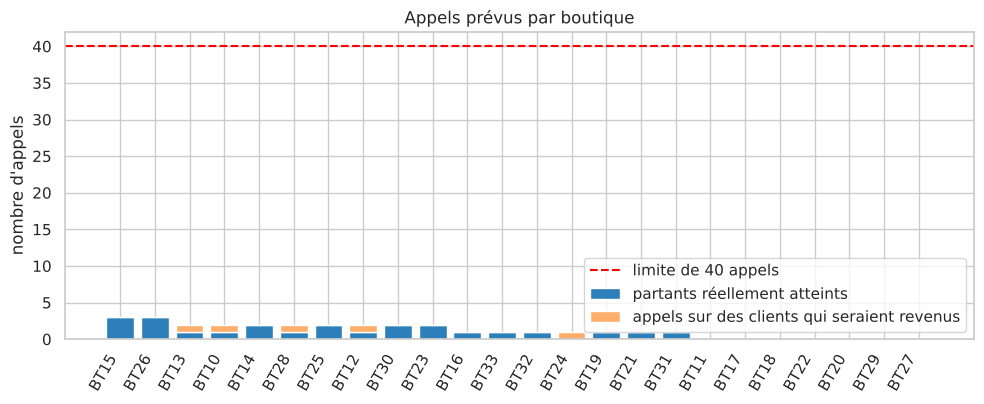

In [12]:
ordre = resume.sort_values("appels", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(ordre.index, ordre["partants_atteints"], color="#2c7fb8", label="partants réellement atteints")
ax.bar(ordre.index, ordre["appels_non_utiles"], bottom=ordre["partants_atteints"], color="#fdae6b",
       label="appels sur des clients qui seraient revenus")
ax.axhline(NB_APPELS_MAX, color="red", linestyle="--", label=f"limite de {NB_APPELS_MAX} appels")
ax.set_ylabel("nombre d'appels")
ax.set_title("Appels prévus par boutique")
plt.xticks(rotation=60, ha="right")
ax.legend()
plt.tight_layout()
plt.savefig(DOSSIER_FIG / "lot3_appels_par_boutique.png", dpi=150)
plt.show()

## 6. Est-ce que ça vaut mieux que le hasard ?

On compare notre liste à une liste tirée au hasard avec le même nombre d'appels. Le « lift » indique combien de fois on fait mieux que le hasard.

In [13]:
precision_liste = liste_appels["depart"].mean()
lift = precision_liste / taux_base

print(f"Appels prévus                              : {len(liste_appels)}")
print(f"Précision de notre liste                   : {precision_liste:.1%}")
print(f"Précision d'une liste au hasard            : {taux_base:.1%}")
print(f"Lift (fois mieux que le hasard)            : {lift:.2f}")
print(f"Partants atteints                          : {int(liste_appels['depart'].sum())} sur {int(total_partants)} ({liste_appels['depart'].sum() / total_partants:.1%})")
print(f"Appels sur des clients revenus de toute façon: {int((1 - liste_appels['depart']).sum())}")

Appels prévus                              : 29
Précision de notre liste                   : 82.8%
Précision d'une liste au hasard            : 58.9%
Lift (fois mieux que le hasard)            : 1.41
Partants atteints                          : 24 sur 412 (5.8%)
Appels sur des clients revenus de toute façon: 5


## 7. Export pour la feuille de route (Membre 5)

La liste des clients à appeler, par boutique, pour que la synthèse puisse dire « qui on rappelle ».

In [14]:
(RACINE / "reports").mkdir(exist_ok=True)

liste_appels[["boutique", "client_id", "proba_depart"]].to_csv(
    RACINE / "reports" / "liste_appels_par_boutique.csv", index=False)
resume.to_csv(RACINE / "reports" / "resume_appels_par_boutique.csv")
print("Fichiers écrits dans reports/")

Fichiers écrits dans reports/


## 8. Réponse à la direction

In [15]:
print(f"""Nous proposons d'appeler les clients dont la probabilité de départ dépasse {SEUIL:.2f},
dans la limite de {NB_APPELS_MAX} appels par boutique, en commençant par les plus à risque.
Cela représente {len(liste_appels)} appels par mois pour l'ensemble des boutiques.
Parmi eux, {precision_liste:.0%} sont réellement partis, contre {taux_base:.0%} si on appelait au hasard
(environ {lift:.1f} fois mieux).
Le prix de cette prudence : nous n'atteignons que {liste_appels['depart'].sum() / total_partants:.0%} des partants,
les autres ne sont pas appelés. C'est le choix voulu par la direction.""")

Nous proposons d'appeler les clients dont la probabilité de départ dépasse 0.80,
dans la limite de 40 appels par boutique, en commençant par les plus à risque.
Cela représente 29 appels par mois pour l'ensemble des boutiques.
Parmi eux, 83% sont réellement partis, contre 59% si on appelait au hasard
(environ 1.4 fois mieux).
Le prix de cette prudence : nous n'atteignons que 6% des partants,
les autres ne sont pas appelés. C'est le choix voulu par la direction.


## Limites à garder en tête

- La précision est mesurée sur des clients dont on connaît déjà la suite, avec des prédictions hors échantillon. En vrai, elle dépendra de la qualité du modèle sur les nouveaux clients.
- Un appel peut lui-même changer le comportement du client. Nous mesurons ici le risque de départ, pas l'effet de l'appel.
- Le nombre d'appels par vendeur varie beaucoup entre boutiques (voir le tableau du paragraphe 5) : une boutique avec peu de vendeurs aura plus de mal à tenir ses 40 appels.
- Si le Membre 1 modifie le nettoyage, il faut relancer 05 puis 06 (Kernel, Restart & Run All).